# 04 · CW-MPVR: our method

**Purpose**
- Implement CW-MPVR from scratch, tune it on the **calibration set only**, then evaluate once on the evaluation set.
- Ablations show which part of the method does the work.

**The rule**: for path $i$ of a question

$$s_i = \beta\,a_i + \gamma\,g_i, \qquad w_i = \frac{e^{s_i}}{\sum_j e^{s_j}}, \qquad \hat{y} = \arg\max_y \sum_{i:\,y_i = y} w_i$$

- $a_i$ = answer confidence (mean token log-probability)
- $g_i$ = grounding confidence (log of BLIP-2 ITM match probability of the evidence)
- $\beta, \gamma \ge 0$ set how much each signal counts

**One rule, many methods**

| Setting | Method |
|---|---|
| $\beta = \gamma = 0$ | Majority vote |
| $\gamma = 0$ | Answer-only weighting |
| $\beta = 0$ | Grounding-only weighting |
| $\beta = \gamma$ | One combined confidence (no decomposition) |
| $\beta, \gamma$ free | **CW-MPVR** (decomposed) |

**Runtime:** CPU (everything reads the cache).

## 1 · Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys
REPO_DIR = "/content/drive/MyDrive/cw-mpvr"
%cd {REPO_DIR}
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from src.utils import load_config, set_seed
from src.errorlog import log_error
from src.gitsync import save_and_push

cfg = load_config()
set_seed(cfg["seed"])
SEED = cfg["seed"]

Mounted at /content/drive
/content/drive/MyDrive/cw-mpvr


## 2 · CW-MPVR code
- Writes `src/cwmpvr.py`: scoring, weighting, grid search, per-question confidence features.
- Built on the from-scratch voting in `src/aggregate.py` (notebook 03).

In [2]:
%%writefile src/cwmpvr.py
"""CW-MPVR: Confidence-Weighted Multi-Path Visual Reasoning, implemented from scratch.

Each path i of a question gets a score from two separate confidence signals:

    s_i = beta * a_i + gamma * g_i
    a_i = mean log-probability of the answer tokens        (answer confidence)
    g_i = log P(match | image, evidence) from BLIP-2 ITM    (grounding confidence)

Weights are a softmax of s_i within the question; the answer with the largest
total weight wins. Special cases of the same rule:
    beta = gamma = 0  -> majority vote (self-consistency)
    gamma = 0         -> answer-only weighting
    beta = 0          -> grounding-only weighting
    beta = gamma      -> one combined (non-decomposed) confidence
"""

import itertools

import numpy as np
import pandas as pd

from .aggregate import softmax_weights, weighted_vote

EPS = 1e-6


def grounding_signal(paths: pd.DataFrame, kind: str = "itm") -> np.ndarray:
    """ITM is a probability -> use its log; ITC is a similarity -> use as is."""
    v = paths[kind].values.astype(float)
    return np.log(np.clip(v, EPS, 1.0)) if kind == "itm" else v


def path_scores(paths, beta, gamma, grounding="itm"):
    return beta * paths["lp_mean"].values + gamma * grounding_signal(paths, grounding)


def cw_mpvr(paths, beta, gamma, grounding="itm") -> pd.DataFrame:
    """Predicted answer and support (winning weight share) for every question."""
    w = softmax_weights(paths, path_scores(paths, beta, gamma, grounding))
    return weighted_vote(paths, w)


def accuracy(pred: pd.Series, gold: pd.Series, sample_weight=None) -> float:
    ok = (pred.reindex(gold.index) == gold).values
    return float(np.average(ok, weights=sample_weight))


def grid_search(paths, gold, betas, gammas, grounding="itm", sample_weight=None) -> pd.DataFrame:
    """Accuracy of every (beta, gamma) pair on a labelled split (calibration only)."""
    rows = []
    for b, g in itertools.product(betas, gammas):
        pred = cw_mpvr(paths, b, g, grounding)["answer"]
        rows.append({"beta": b, "gamma": g, "acc": accuracy(pred, gold, sample_weight)})
    return pd.DataFrame(rows)


def select(grid: pd.DataFrame) -> pd.Series:
    """Highest accuracy; ties go to the simplest setting (smallest beta + gamma)."""
    g = grid.assign(size=grid["beta"] + grid["gamma"])
    return g.sort_values(["acc", "size"], ascending=[False, True]).iloc[0]


def question_features(paths, pred: pd.DataFrame, grounding="itm") -> pd.DataFrame:
    """Per-question confidence features for calibration and abstention (notebook 05)."""
    p = paths.assign(win=paths["answer"].values == pred["answer"].reindex(paths["id"]).values)
    agree = p.groupby("id")["win"].mean()
    sup = p[p["win"]].groupby("id")
    return pd.DataFrame({
        "support": pred["support"],
        "agreement": agree,                                  # share of paths giving the answer
        "answer_conf": sup["lp_mean"].mean(),                # answer confidence of those paths
        "grounding_conf": sup[grounding].mean(),             # grounding confidence of those paths
    })

Writing src/cwmpvr.py


In [3]:
import importlib, os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import src.paths, src.aggregate as A, src.evaluate as E, src.cwmpvr as C
for m in (src.paths, A, E, C):
    importlib.reload(m)

HIGHLIGHT, BASE, LIGHT, INK, MUTED = "#eb6834", "#2a78d6", "#b9b8b2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.titleweight": "bold", "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})

read = lambda f: pd.read_csv(f, dtype={"id": str, "imageId": str})
meta = {"eval": read("data/eval_testdev.csv").set_index("id"), "calib": read("data/calib_val.csv").set_index("id")}
GOLD = {s: meta[s]["answer"].map(src.paths.normalize) for s in meta}
Q, PTH = {}, {}
for s in meta:
    Q[s], PTH[s] = A.load_paths(f"results/paths_{s}.jsonl.gz")
    Q[s] = Q[s].set_index("id")
print({s: len(PTH[s]) for s in PTH}, "paths")

{'eval': 25000, 'calib': 5000} paths


## 3 · Tune on the calibration set
- Grid search over $\beta$ (answer) and $\gamma$ (grounding): 7 × 8 = 56 settings.
- Only the 500 calibration (val) questions are used → the evaluation set stays untouched.
- Ties go to the simplest setting.

selected: beta = 2.0, gamma = 8.0  ->  calib accuracy 44.8%


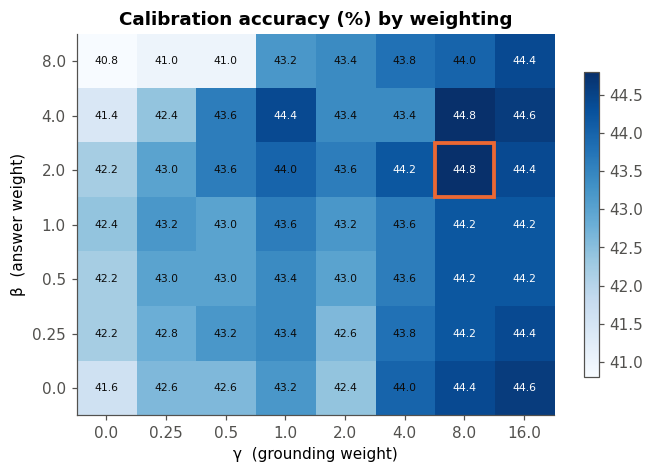

In [4]:
BETAS  = [0, 0.25, 0.5, 1, 2, 4, 8]
GAMMAS = [0, 0.25, 0.5, 1, 2, 4, 8, 16]

grid = C.grid_search(PTH["calib"], GOLD["calib"], BETAS, GAMMAS)
best = C.select(grid)
grid.to_csv("results/04_grid_calib.csv", index=False)
print(f"selected: beta = {best.beta}, gamma = {best.gamma}  ->  calib accuracy {100 * best.acc:.1f}%")

def heatmap(ax, grid, title, mark=None):
    m = grid.pivot(index="beta", columns="gamma", values="acc") * 100
    im = ax.imshow(m.values, cmap="Blues", aspect="auto", origin="lower")
    ax.set_xticks(range(len(m.columns)), m.columns); ax.set_yticks(range(len(m.index)), m.index)
    ax.set_xlabel("γ  (grounding weight)"); ax.set_ylabel("β  (answer weight)"); ax.grid(False)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.values[i, j]
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7,
                    color="white" if v > np.nanpercentile(m.values, 70) else INK)
    if mark is not None:
        i, j = list(m.index).index(mark.beta), list(m.columns).index(mark.gamma)
        ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, edgecolor=HIGHLIGHT, linewidth=2.5))
    ax.set_title(title)
    return im

fig, ax = plt.subplots(figsize=(7, 4.5))
im = heatmap(ax, grid, "Calibration accuracy (%) by weighting", best)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.savefig("figures/04_grid_calib.png"); plt.show()

## 4 · Ablations: which signal does the work?
- Each variant is tuned on calibration in the same way, but with some weights fixed.
- **ITC variant**: swaps the grounding signal for the cheaper image-text similarity (different scale → larger γ grid).

In [5]:
GAMMAS_ITC = [0, 5, 10, 20, 40, 80, 160]
LAMBDAS = sorted(set(BETAS[1:] + GAMMAS[1:]))

def tuned(betas, gammas, grounding="itm"):
    g = C.grid_search(PTH["calib"], GOLD["calib"], betas, gammas, grounding)
    b = C.select(g)
    return {"beta": float(b.beta), "gamma": float(b.gamma), "grounding": grounding, "calib_acc": 100 * b.acc}

tied = pd.DataFrame([{"beta": l, "gamma": l,
                      "acc": C.accuracy(C.cw_mpvr(PTH["calib"], l, l)["answer"], GOLD["calib"])} for l in LAMBDAS])
tb = C.select(tied)

VARIANTS = {
    "Answer-only (tuned)": tuned(BETAS, [0]),
    "Grounding-only":      tuned([0], GAMMAS),
    "Tied (β = γ)":        {"beta": float(tb.beta), "gamma": float(tb.gamma), "grounding": "itm", "calib_acc": 100 * tb.acc},
    "CW-MPVR (ITC)":       tuned(BETAS, GAMMAS_ITC, "itc"),
    "CW-MPVR":             {"beta": float(best.beta), "gamma": float(best.gamma), "grounding": "itm", "calib_acc": 100 * best.acc},
}
json.dump(VARIANTS, open("results/04_params.json", "w"), indent=2)
pd.DataFrame(VARIANTS).T.round(2)

,beta,gamma,grounding,calib_acc
Answer-only (tuned),1.0,0.0,itm,42.4
Grounding-only,0.0,16.0,itm,44.6
Tied (β = γ),8.0,8.0,itm,44.0
CW-MPVR (ITC),2.0,10.0,itc,44.8
CW-MPVR,2.0,8.0,itm,44.8


## 5 · Does the calibration–test type shift matter?
- val has a slightly different mix of question types than testdev (notebook 01).
- Re-tune with calibration questions **re-weighted** to testdev's type mix; if the chosen setting barely moves, the shift is harmless.

In [6]:
cell = lambda d: d["structural"] + "/" + d["semantic"]
p_test = cell(meta["eval"]).value_counts(normalize=True)
p_cal = cell(meta["calib"]).value_counts(normalize=True)
w = cell(meta["calib"]).map(p_test / p_cal).fillna(0).reindex(GOLD["calib"].index).values

grid_rw = C.grid_search(PTH["calib"], GOLD["calib"], BETAS, GAMMAS, sample_weight=w)
best_rw = C.select(grid_rw)
r = np.corrcoef(grid.acc, grid_rw.acc)[0, 1]
print(f"unweighted choice: beta={best.beta}, gamma={best.gamma}")
print(f"re-weighted choice: beta={best_rw.beta}, gamma={best_rw.gamma}")
print(f"correlation of the two accuracy surfaces: {r:.3f}")

unweighted choice: beta=2.0, gamma=8.0
re-weighted choice: beta=2.0, gamma=8.0
correlation of the two accuracy surfaces: 0.986


## 6 · Final evaluation (2,500 testdev questions)
- Settings are **locked** from Steps 3–4; this is the first time CW-MPVR sees the evaluation set.
- Oracle = a path with the right answer exists → upper bound for any voting rule.

In [7]:
def predict(s):
    p, q = PTH[s], Q[s]
    out = pd.DataFrame(index=q.index)
    out["Greedy"] = q["greedy"]
    out["Majority vote"] = A.majority(p)["answer"]
    out["Answer-only"] = A.answer_only(p)["answer"]
    for name, v in VARIANTS.items():
        out[name] = C.cw_mpvr(p, v["beta"], v["gamma"], v["grounding"])["answer"]
    return out

preds = {s: predict(s) for s in meta}
correct = preds["eval"].reindex(GOLD["eval"].index).eq(GOLD["eval"], axis=0)
oracle = PTH["eval"].assign(ok=PTH["eval"].answer.values == GOLD["eval"].reindex(PTH["eval"].id).values).groupby("id").ok.any()
correct["Oracle (upper bound)"] = oracle.reindex(correct.index)

IMG = meta["eval"]["imageId"].reindex(correct.index).values
table = E.accuracy_table(correct, IMG, SEED)
table.to_csv("results/04_ablation_eval.csv")
table

,accuracy,ci_low,ci_high
Greedy,40.20,38.16,42.23
Majority vote,40.68,38.62,42.74
Answer-only,41.12,39.01,43.22
Answer-only (tuned),41.12,39.01,43.22
Grounding-only,39.48,37.42,41.56
Tied (β = γ),39.24,37.12,41.32
CW-MPVR (ITC),40.48,38.37,42.53
CW-MPVR,39.60,37.51,41.66
Oracle (upper bound),59.80,57.62,61.94


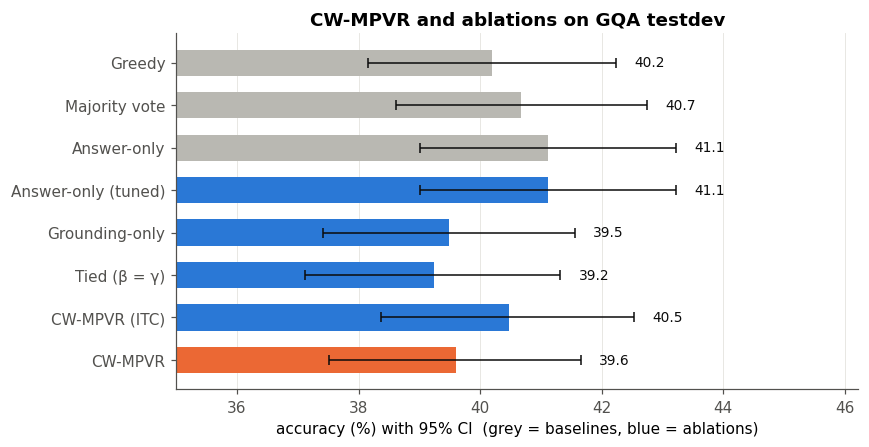

For reference: LXMERT (supervised) 59.2%, oracle 59.8%


In [8]:
show = table.drop(index="Oracle (upper bound)")
lx = pd.read_csv("results/03_benchmarks.csv", index_col=0).loc["LXMERT", "accuracy"]
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(show))[::-1]
cols = [HIGHLIGHT if m == "CW-MPVR" else (LIGHT if m in ("Greedy", "Majority vote", "Answer-only") else BASE) for m in show.index]
ax.barh(y, show.accuracy, color=cols, height=0.62)
ax.errorbar(show.accuracy, y, xerr=[show.accuracy - show.ci_low, show.ci_high - show.accuracy],
            fmt="none", ecolor=INK, capsize=3, linewidth=1)
for yi, v, hi in zip(y, show.accuracy, show.ci_high):
    ax.text(hi + 0.3, yi, f"{v:.1f}", va="center", fontsize=9, color=INK)
ax.set_yticks(y, show.index); ax.grid(axis="y", visible=False)
lo = np.floor(show.ci_low.min() - 2)
ax.set_xlim(lo, show.ci_high.max() + 3)
ax.set_xlabel("accuracy (%) with 95% CI  (grey = baselines, blue = ablations)")
ax.set_title("CW-MPVR and ablations on GQA testdev")
plt.savefig("figures/04_ablations.png"); plt.show()
print(f"For reference: LXMERT (supervised) {lx:.1f}%, oracle {table.loc['Oracle (upper bound)', 'accuracy']:.1f}%")

## 7 · Is the improvement significant?
- Same paired tests as notebook 03: exact McNemar and image-clustered paired bootstrap.
- Full multiple-comparison correction and per-type tests follow in notebook 05.

In [9]:
def compare(a, b):
    bs = E.paired_bootstrap(correct[a], correct[b], IMG, seed=SEED)
    return {"A": a, "B": b, "A − B (pts)": 100 * bs["diff"], **E.mcnemar(correct[a], correct[b]),
            "CI low": 100 * bs["ci_lo"], "CI high": 100 * bs["ci_hi"], "p_boot": bs["p_boot"]}

pairs = [("CW-MPVR", "Greedy"), ("CW-MPVR", "Majority vote"), ("CW-MPVR", "Answer-only"),
         ("CW-MPVR", "Answer-only (tuned)"), ("CW-MPVR", "Tied (β = γ)"), ("Grounding-only", "Answer-only (tuned)")]
tests = pd.DataFrame([compare(a, b) for a, b in pairs])
tests.to_csv("results/04_tests.csv", index=False)
tests.round(4)

,A,B,A − B (pts),only_A,only_B,p_mcnemar,CI low,CI high,p_boot
0,CW-MPVR,Greedy,-0.60,126,141,0.3916,-1.9086,0.7550,0.3968
1,CW-MPVR,Majority vote,-1.08,100,127,0.0842,-2.3566,0.1670,0.1068
2,CW-MPVR,Answer-only,-1.52,95,133,0.0141,-2.8193,-0.2119,0.0260
3,CW-MPVR,Answer-only (tuned),-1.52,95,133,0.0141,-2.8193,-0.2119,0.0260
4,CW-MPVR,Tied (β = γ),0.36,30,21,0.2624,-0.2493,0.9718,0.2676
5,Grounding-only,Answer-only (tuned),-1.64,101,142,0.0101,-2.9540,-0.2905,0.0160


## 8 · Sensitivity: is the result fragile?
- Left: calibration grid (used for selection). Right: same grid on evaluation (**not** used for selection, only to check robustness).
- A broad high region (rather than one lucky cell) means the result does not hinge on the exact setting.

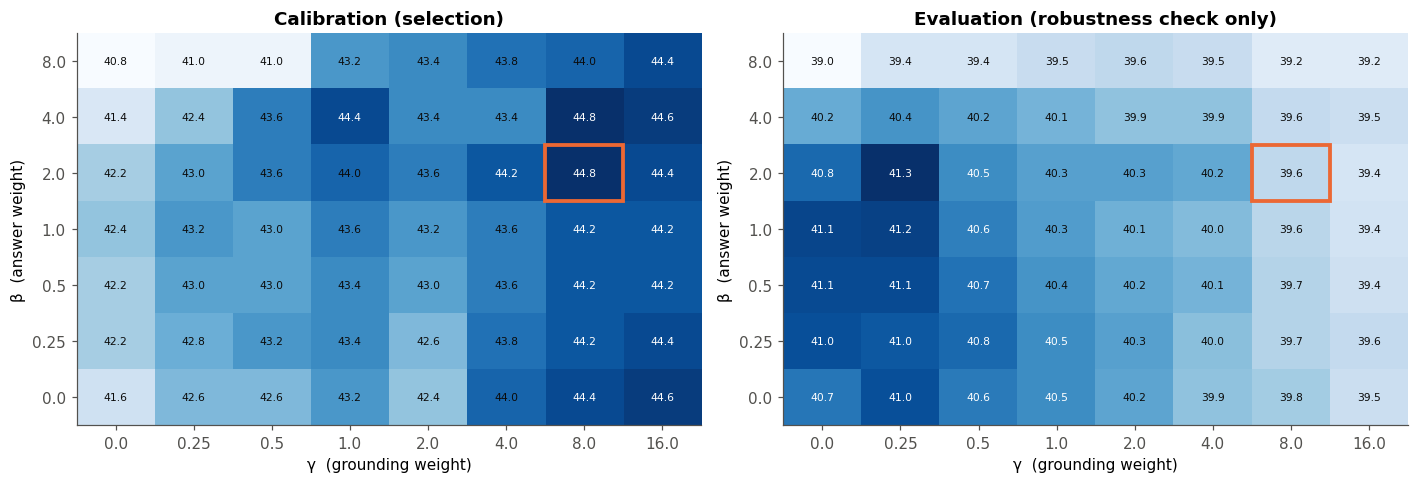

correlation between calibration and evaluation surfaces: -0.332


In [10]:
grid_eval = C.grid_search(PTH["eval"], GOLD["eval"], BETAS, GAMMAS)
grid_eval.to_csv("results/04_grid_eval.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
heatmap(axes[0], grid, "Calibration (selection)", best)
heatmap(axes[1], grid_eval, "Evaluation (robustness check only)", best)
plt.tight_layout(); plt.savefig("figures/04_sensitivity.png"); plt.show()
print(f"correlation between calibration and evaluation surfaces: {np.corrcoef(grid.acc, grid_eval.acc)[0, 1]:.3f}")

## 9 · How many paths are needed?
- For k = 1 … 10, keep k random paths per question (20 repeats) and re-run each method.
- Shows the accuracy / compute trade-off: each extra path costs one more generation.

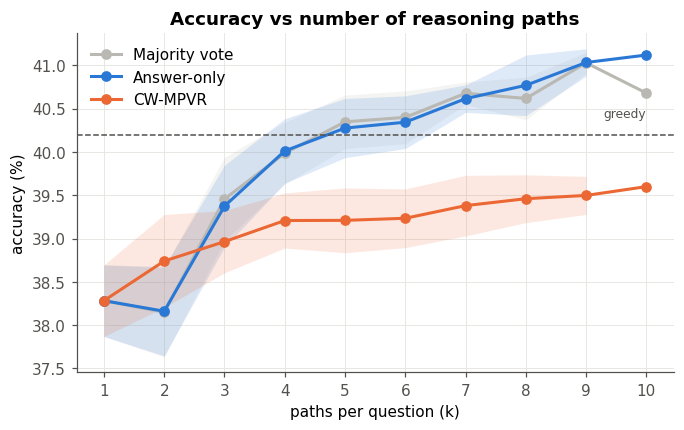

method,Answer-only,CW-MPVR,Majority vote
k,,,
1,38.28,38.28,38.28
2,38.16,38.74,38.15
3,39.37,38.96,39.46
4,40.01,39.21,39.99
5,40.28,39.21,40.35
6,40.34,39.23,40.40
7,40.62,39.38,40.68
8,40.77,39.46,40.62
9,41.03,39.50,41.03


In [11]:
def subset(p, k, rng):
    r = pd.Series(rng.random(len(p)), index=p.index)
    return p[r.groupby(p["id"]).rank(method="first") <= k]

cw = VARIANTS["CW-MPVR"]
methods = {"Majority vote": lambda p: A.majority(p),
           "Answer-only": lambda p: A.answer_only(p),
           "CW-MPVR": lambda p: C.cw_mpvr(p, cw["beta"], cw["gamma"])}
rng = np.random.default_rng(SEED)
rows = []
for k in range(1, 11):
    for rep in range(20 if k < 10 else 1):
        sp = subset(PTH["eval"], k, rng)
        for m, f in methods.items():
            rows.append({"k": k, "method": m, "acc": 100 * C.accuracy(f(sp)["answer"], GOLD["eval"])})
ks = pd.DataFrame(rows).groupby(["k", "method"]).acc.agg(["mean", "std"]).reset_index()
ks.to_csv("results/04_k_sweep.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
for m, c in [("Majority vote", LIGHT), ("Answer-only", BASE), ("CW-MPVR", HIGHLIGHT)]:
    d = ks[ks.method == m]
    ax.plot(d.k, d["mean"], "-o", color=c, linewidth=2, markersize=6, label=m)
    ax.fill_between(d.k, d["mean"] - d["std"], d["mean"] + d["std"], color=c, alpha=0.15, linewidth=0)
ax.axhline(table.loc["Greedy", "accuracy"], color=MUTED, linestyle="--", linewidth=1)
ax.text(10, table.loc["Greedy", "accuracy"] + 0.2, "greedy", ha="right", fontsize=8, color=MUTED)
ax.set_xticks(range(1, 11)); ax.set_xlabel("paths per question (k)"); ax.set_ylabel("accuracy (%)")
ax.set_title("Accuracy vs number of reasoning paths"); ax.legend()
plt.savefig("figures/04_k_sweep.png"); plt.show()
ks.pivot(index="k", columns="method", values="mean").round(2)

## 10 · Computational and memory complexity
**Generation (notebook 02, once)** — N questions, k paths, evidence length $L_e$, answer length $L_a$
- Time: $O(N \cdot k \cdot (L_e + L_a))$ decoder steps + $O(N \cdot k)$ ITM passes; measured **≈1.6 s / question** on an L4 (≈80 min for 3,000 questions).
- Memory: BLIP-2 FlanT5-XL (bf16) + ITM (fp16) ≈ **11 GB GPU**; constant in N (one question at a time).
- Cost grows **linearly in k** → the k-sweep above shows how much accuracy each path buys.

**Aggregation (this notebook)**
- Time: $O(N \cdot k)$ (one softmax and one group-by per question); grid search multiplies by the grid size $|B| \cdot |\Gamma|$.
- Memory: $O(N \cdot k)$ for the path table.
- No GPU, no training → measured below.

In [12]:
t = time.perf_counter()
for _ in range(5):
    C.cw_mpvr(PTH["eval"], cw["beta"], cw["gamma"])
per_run = (time.perf_counter() - t) / 5
mem = PTH["eval"].memory_usage(deep=True).sum() / 1e6
print(f"CW-MPVR aggregation over {len(PTH['eval']):,} paths: {1000 * per_run:.0f} ms "
      f"({1e6 * per_run / len(Q['eval']):.0f} µs per question) | path table {mem:.1f} MB")

CW-MPVR aggregation over 25,000 paths: 70 ms (28 µs per question) | path table 4.0 MB


## 11 · Save predictions and confidence features
- Notebook 05 uses these for statistics, calibration, abstention and error analysis.

In [13]:
for s in meta:
    pr = C.cw_mpvr(PTH[s], cw["beta"], cw["gamma"])
    feats = C.question_features(PTH[s], pr).add_prefix("cw_")
    maj = A.majority(PTH[s])
    out = preds[s].join(feats).join(maj["support"].rename("majority_support"))
    out["greedy_conf"] = Q[s]["greedy_lp"]
    out.index.name = "id"
    out.reindex(GOLD[s].index).to_csv(f"results/04_predictions_{s}.csv")
print(out.columns.tolist())

['Greedy', 'Majority vote', 'Answer-only', 'Answer-only (tuned)', 'Grounding-only', 'Tied (β = γ)', 'CW-MPVR (ITC)', 'CW-MPVR', 'cw_support', 'cw_agreement', 'cw_answer_conf', 'cw_grounding_conf', 'majority_support', 'greedy_conf']


## 12 · Save to GitHub

In [ ]:
save_and_push("notebooks/04_cwmpvr.ipynb", "Add CW-MPVR: calibration tuning, ablations, k-sweep, complexity")